In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("online_retail.csv")

print("Dataset loaded successfully")

Dataset loaded successfully


In [4]:
print("Dataset Shape:", df.shape)

Dataset Shape: (35196, 8)


In [5]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12.0,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12.0,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12.0,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48.0,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24.0,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [6]:
df.describe()

,Quantity,Price,Customer ID
count,35195.000000,35195.00000,26007.000000
mean,9.322375,4.22074,15475.097128
std,63.155251,21.52357,1651.371122
min,-1395.000000,0.00000,12346.000000
25%,1.000000,1.25000,14087.000000
50%,3.000000,2.57000,15527.000000
75%,8.000000,4.95000,16918.000000
max,5184.000000,1998.49000,18287.000000


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35196 entries, 0 to 35195
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Invoice      35196 non-null  object 
 1   StockCode    35195 non-null  object 
 2   Description  35121 non-null  object 
 3   Quantity     35195 non-null  float64
 4   InvoiceDate  35195 non-null  object 
 5   Price        35195 non-null  float64
 6   Customer ID  26007 non-null  float64
 7   Country      35195 non-null  object 
dtypes: float64(3), object(5)
memory usage: 2.1+ MB


In [8]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score

In [9]:
df = df.dropna(subset=["Customer ID"])

df = df[df["Quantity"] > 0]

df = df[df["Price"] > 0]

df = df[~df["Invoice"].astype(str).str.startswith("C")]

df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

df["TotalPrice"] = df["Quantity"] * df["Price"]

In [10]:
print("Shape after cleaning:", df.shape)

Shape after cleaning: (25222, 9)


In [11]:
reference_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

In [12]:
rfm = df.groupby("Customer ID").agg({
    "InvoiceDate": lambda x: (reference_date - x.max()).days,
    "Invoice": "nunique",
    "TotalPrice": "sum"
})

In [13]:
rfm.columns = ["Recency", "Frequency", "Monetary"]

In [14]:
print(rfm.head())

print("\nRFM Dataset Shape:", rfm.shape)

             Recency  Frequency  Monetary
Customer ID                              
12346.0            3          3     90.00
12358.0            9          1   1429.83
12359.0           11          1    760.69
12362.0           16          1    130.00
12417.0            7          2    317.60

RFM Dataset Shape: (852, 3)


In [15]:
scaler = StandardScaler()

X = scaler.fit_transform(rfm)

In [16]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

rfm["KMeans_Cluster"] = kmeans.fit_predict(X)

In [17]:
score = silhouette_score(X, rfm["KMeans_Cluster"])

print("K-Means Silhouette Score:", round(score, 4))

K-Means Silhouette Score: 0.4521


In [18]:
dbscan = DBSCAN(
    eps=0.8,
    min_samples=5
)

rfm["DBSCAN_Cluster"] = dbscan.fit_predict(X)

In [19]:
cluster_analysis = rfm.groupby("KMeans_Cluster")[
    ["Recency", "Frequency", "Monetary"]
].mean()

print(cluster_analysis)

                  Recency  Frequency      Monetary
KMeans_Cluster                                    
0               11.990431   1.088517    369.331029
1                2.500000  10.000000  14919.561667
2                3.990654   1.649533    727.656939


In [20]:
print("K-Means Cluster Distribution:")

print(rfm["KMeans_Cluster"].value_counts())

K-Means Cluster Distribution:
KMeans_Cluster
2    428
0    418
1      6
Name: count, dtype: int64


In [21]:
print("DBSCAN Cluster Distribution:")

print(rfm["DBSCAN_Cluster"].value_counts())

DBSCAN Cluster Distribution:
DBSCAN_Cluster
 1    636
 2    141
 0     39
-1     24
 3     12
Name: count, dtype: int64


In [22]:
pca = PCA(n_components=2)

pca_result = pca.fit_transform(X)

print("Variance Explained:", pca.explained_variance_ratio_)

print(
    "Total Variance Explained:",
    round(sum(pca.explained_variance_ratio_) * 100, 2),
    "%"
)

Variance Explained: [0.57248759 0.28794051]
Total Variance Explained: 86.04 %


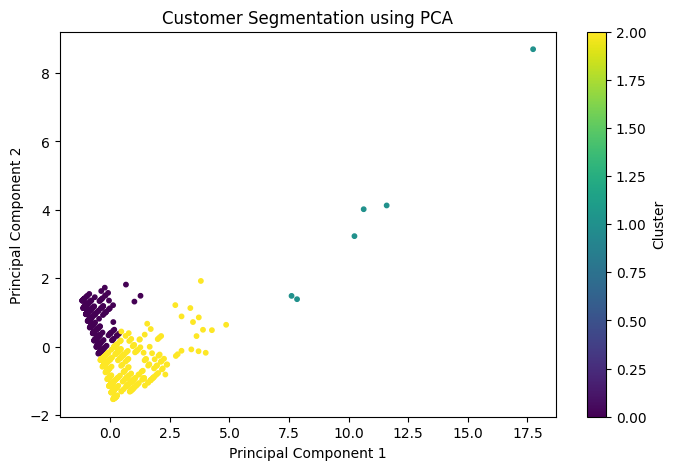

In [23]:
plt.figure(figsize=(8, 5))

plt.scatter(
    pca_result[:, 0],
    pca_result[:, 1],
    c=rfm["KMeans_Cluster"],
    cmap="viridis",
    s=10
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Customer Segmentation using PCA")

plt.colorbar(label="Cluster")

plt.show()

In [24]:
tsne = TSNE(
    n_components=2,
    random_state=42,
    perplexity=min(30, len(rfm) - 1)
)

In [25]:
tsne_result = tsne.fit_transform(X)

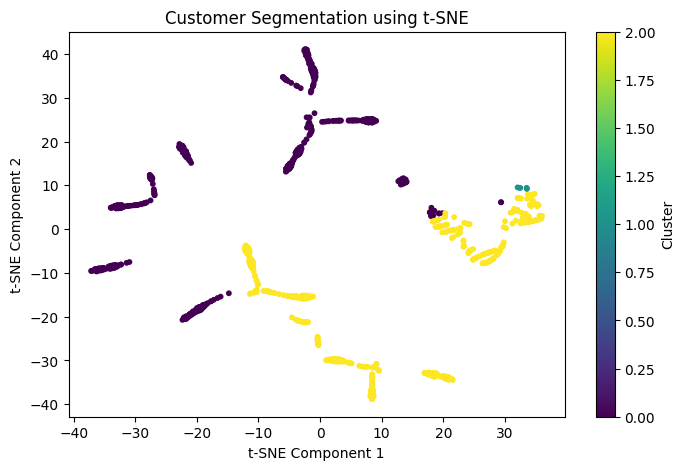

In [26]:
plt.figure(figsize=(8, 5))

plt.scatter(
    tsne_result[:, 0],
    tsne_result[:, 1],
    c=rfm["KMeans_Cluster"],
    cmap="viridis",
    s=10
)

plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")
plt.title("Customer Segmentation using t-SNE")

plt.colorbar(label="Cluster")

plt.show()

In [27]:
for cluster in sorted(rfm["KMeans_Cluster"].unique()):

    group = rfm[rfm["KMeans_Cluster"] == cluster]

    recency = group["Recency"].mean()
    frequency = group["Frequency"].mean()
    monetary = group["Monetary"].mean()

    print("\nCluster:", cluster)

    print("Average Recency:", round(recency, 2))
    print("Average Frequency:", round(frequency, 2))
    print("Average Monetary:", round(monetary, 2))

    if (
        recency < rfm["Recency"].median()
        and frequency > rfm["Frequency"].median()
    ):
        print("Persona: Loyal or Active Customers")

    elif recency > rfm["Recency"].median():
        print("Persona: Inactive or At-Risk Customers")

    else:
        print("Persona: Occasional Customers")


Cluster: 0
Average Recency: 11.99
Average Frequency: 1.09
Average Monetary: 369.33
Persona: Inactive or At-Risk Customers

Cluster: 1
Average Recency: 2.5
Average Frequency: 10.0
Average Monetary: 14919.56
Persona: Loyal or Active Customers

Cluster: 2
Average Recency: 3.99
Average Frequency: 1.65
Average Monetary: 727.66
Persona: Loyal or Active Customers


In [28]:
print("\nFinal Customer Segmentation")

print(
    rfm.groupby("KMeans_Cluster")[
        ["Recency", "Frequency", "Monetary"]
    ].mean()
)


Final Customer Segmentation
                  Recency  Frequency      Monetary
KMeans_Cluster                                    
0               11.990431   1.088517    369.331029
1                2.500000  10.000000  14919.561667
2                3.990654   1.649533    727.656939


In [29]:
rfm.head(10)


,Recency,Frequency,Monetary,KMeans_Cluster,DBSCAN_Cluster
Customer ID,,,,,
12346.0,3,3,90.00,2,0
12358.0,9,1,1429.83,0,1
12359.0,11,1,760.69,0,1
12362.0,16,1,130.00,0,1
12417.0,7,2,317.60,2,2
12435.0,14,1,1008.00,0,1
12437.0,14,1,578.28,0,1
12439.0,3,1,1081.66,2,1
12443.0,9,1,485.31,0,1
